# Phase E: Embedding zur Fehlererkennung

Schritte 15 bis 17 aus `LERNPLAN.md`.

## Setup

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
LERNPFAD = ROOT / "data" / "processed" / "lernpfad"
BILDER = ROOT / "docs" / "assets" / "lernpfad"

sys.path.insert(0, str(ROOT))

## Schritt 15: Ein Steckbrief pro Station

Aus Phase D gibt es für jeden Tag 8 Zahlen. Dazu die Tabelle, welcher Tag zu welchem Zähler gehört:

In [2]:
emb = np.load(LERNPFAD / "embedding_tage.npy")
info = pd.read_csv(LERNPFAD / "info_tage.csv", parse_dates=["tag"])
emb.shape

(24684, 8)

Der Steckbrief einer Station ist der Durchschnitt der 8 Zahlen über alle ihre Tage, so wie die Zeugnisnote aus den einzelnen Noten:

In [3]:
steckbrief = pd.DataFrame(emb).groupby(info["zaehler"]).mean()
steckbrief.shape

(54, 8)

Wie viel Winter steckt in jedem Durchschnitt? Anteil der Tage von November bis März je Station:

In [4]:
winter = info["tag"].dt.month.isin([11, 12, 1, 2, 3])
anteil = winter.groupby(info["zaehler"]).mean()
anteil.describe()

count    54.000000
mean      0.457987
std       0.050265
min       0.416938
25%       0.426136
50%       0.441628
75%       0.482342
max       0.646789
Name: tag, dtype: float64

Zwischen 42 und 65 % der Tage liegen im Winter. Eine Station mit vielen Wintertagen hätte einen „kälteren“ Steckbrief, ohne dass mit ihr etwas anders ist. Deshalb nur Tage von November bis März, jede Station hat davon mindestens 141:

In [5]:
steckbrief_winter = pd.DataFrame(emb[winter.values]).groupby(info["zaehler"][winter].values).mean()
steckbrief_winter.shape

(54, 8)

### Wiedererkennung über zwei Winter

Wenn die 8 Zahlen beschreiben, wie eine Station tickt, muss man sie ein Jahr später wiedererkennen. Dafür je ein Steckbrief aus dem Winter 2022/23 und 2023/24. Im ersten Winter gibt es erst 23 Stationen, alle sind auch im zweiten dabei:

In [6]:
w1 = (info["tag"] >= "2022-11-01") & (info["tag"] < "2023-04-01")
w2 = (info["tag"] >= "2023-11-01") & (info["tag"] < "2024-04-01")

s1 = pd.DataFrame(emb[w1.values]).groupby(info["zaehler"][w1].values).mean() 
s2 = pd.DataFrame(emb[w2.values]).groupby(info["zaehler"][w2].values).mean() 

s1.shape, s2.shape

((23, 8), (54, 8))

Wie ähnlich sind sich zwei Steckbriefe? Der Abstand ist die Luftlinie zwischen den beiden Listen von 8 Zahlen, klein heißt ähnlich. `cdist` rechnet ihn von jeder Station aus Winter 1 (Zeilen) zu jeder aus Winter 2 (Spalten) aus:

In [7]:
from scipy.spatial.distance import cdist

abstand = cdist(s1, s2)
abstand.shape

(23, 54)

In jeder Zeile die Spalte mit dem kleinsten Abstand. Ist das dieselbe Station, ist sie wiedererkannt. Blind geraten wären es 23 × 1/54 ≈ 0,4 Treffer:

In [8]:
naechster = s2.index[abstand.argmin(axis=1)]
treffer = naechster == s1.index
treffer.sum()

np.int64(19)

### Vergleich mit einfachen Steckbriefen

19 von 23, aber ist das ein Verdienst des LSTM? Zum Vergleich ein Steckbrief ohne LSTM: die Mittelwerte von Rücklauf, Durchfluss und Vorlauf im Winter (3 Zahlen):

In [9]:
X = np.load(LERNPFAD / "X_tage.npy")
tagesmittel = X[:, :, :3].mean(axis=1)
k1 = pd.DataFrame(tagesmittel[w1.values]).groupby(info["zaehler"][w1].values).mean()
k2 = pd.DataFrame(tagesmittel[w2.values]).groupby(info["zaehler"][w2].values).mean()
k2.round(1).head()

,0,1,2
65273846,27.7,61.3,52.8
68956339,48.5,276.0,73.7
68956342,43.2,196.2,69.7
68956344,52.3,132.6,68.3
68956345,51.0,201.5,75.6


Der Durchfluss hat in l/h viel größere Zahlen (Streuung etwa 142 l/h gegen 10 °C beim Rücklauf) und würde den Abstand fast allein bestimmen. Deshalb vorher standardisieren, mit Mittelwert und Streuung aus Winter 2 für beide Winter:

In [10]:
m = k2.mean()
s = k2.std()
abstand_k = cdist((k1 - m) / s, (k2 - m) / s)
naechster_k = k2.index[abstand_k.argmin(axis=1)]
(naechster_k == k1.index).sum()


np.int64(13)

Vielleicht liegt der Vorsprung nur daran, dass das LSTM mehr Zahlen hat. Deshalb noch der typische Wintertag: jede Stunde einzeln gemittelt, 24 × 3 = 72 Zahlen:

In [11]:
profil = X[:, :, :3].reshape(len(X), 72)
p1 = pd.DataFrame(profil[w1.values]).groupby(info["zaehler"][w1].values).mean()
p2 = pd.DataFrame(profil[w2.values]).groupby(info["zaehler"][w2].values).mean()
m = p2.mean()
s = p2.std()
abstand_p = cdist((p1 - m) / s, (p2 - m) / s)
naechster_p = p2.index[abstand_p.argmin(axis=1)]
(naechster_p == p1.index).sum()

np.int64(15)

In [12]:
print(profil)

[[ 24.8   0.   58.7 ...  28.4   0.   30.5]
 [ 24.5  41.   59.7 ...  28.5   0.   30.4]
 [ 26.7   0.   27.8 ...  22.8   0.   26.3]
 ...
 [ 59.    0.   58.6 ...  50.8   0.   48.4]
 [ 43.9   0.   42.5 ...  67.3 370.   70.2]
 [ 59.6   0.   58.4 ...  55.3   0.   54.1]]


### Die Stationen, die nicht erkannt werden

Bei drei davon steht die richtige Station auf Platz 2, 4 und 9. Bei 68956372 erst auf Platz 51 von 54 (Zeile 0 Rücklauf, 1 Durchfluss, 2 Vorlauf):

In [13]:
pd.DataFrame({"Winter 1": k1.loc[68956372], "Winter 2": k2.loc[68956372]}).round(1)

,Winter 1,Winter 2
0,41.4,69.6
1,51.3,318.5
2,62.2,73.1


Rücklauf von 41 auf 70 °C, Durchfluss von 51 auf 318 l/h: Das Wasser läuft durch, ohne seine Wärme abzugeben, wie bei einem offenen Ventil. Bei der Begehung am 14.10.2024 gab es dort einen Ventilbefund. Dass die Station nicht wiedererkannt wird, ist gewollt: Sie verhält sich seit dem Schaden wirklich anders. Das ist die Idee für den Wächter in Phase F.

Zusammen:

Text(0, 0.5, '')

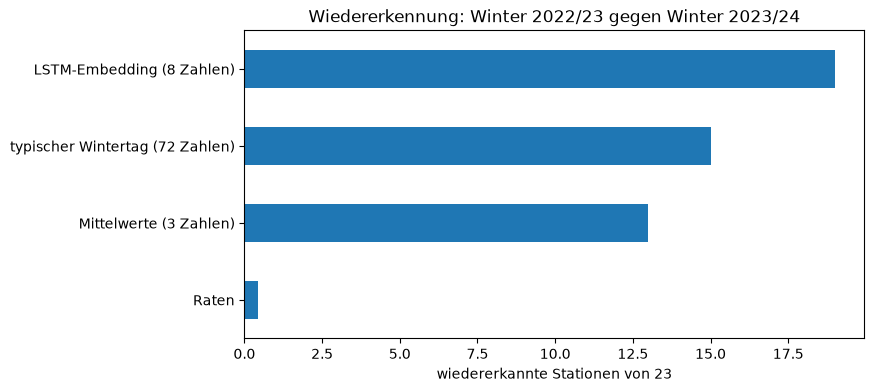

In [14]:
ergebnis = pd.Series({
    "Raten": 23 / 54,
    "Mittelwerte (3 Zahlen)": (naechster_k == k1.index).sum(),
    "typischer Wintertag (72 Zahlen)": (naechster_p == p1.index).sum(),
    "LSTM-Embedding (8 Zahlen)": treffer.sum(),
})
ax = ergebnis.plot.barh(figsize=(8, 4))
ax.set_title("Wiedererkennung: Winter 2022/23 gegen Winter 2023/24")
ax.set_xlabel("wiedererkannte Stationen von 23")
ax.set_ylabel("")

In [15]:
ax.figure.savefig(BILDER / "15_wiedererkennung.png", bbox_inches="tight")

- Raten 0,4, Mittelwerte 13, typischer Wintertag 15, LSTM 19 von 23.
- Mehr Zahlen allein bringen es nicht: 72 Zahlen schaffen weniger als die 8 vom LSTM.
- Das LSTM erkennt alle 15 Stationen des typischen Wintertags und 4 dazu, umgekehrt keine. Viermal Kopf beim Münzwurf passiert aber auch in 1 von 16 Fällen. Ein deutlicher Hinweis, kein Beweis.

## Schritt 16: Findet der Steckbrief die Befunde?

Nur der Steckbrief aus dem Winter 2023/24 (`s2`): Er liegt am nächsten an den Begehungen (ab Ende August 2024), alle 54 Stationen haben ihn, und alle Tage liegen vor der Begehung. Beide Winter gemittelt würden zum Beispiel bei 68956372 den Ventilschaden verwässern.

In [16]:
labels = pd.read_csv(ROOT / "data" / "processed" / "modell_labels.csv", index_col="zaehler")
daten = s2.join(labels)
daten.shape

(54, 19)

Erwartung vor dem Rechnen: Das Embedding findet Ventil, Dämmung und Überdimensionierung, aber nicht Filter, Durchfluss und Temperatur.

In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import LeaveOneOut, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

Logistische Regression wie in Phase B, mit `StandardScaler` und Leave-one-out: Jede Station wird einmal weggelassen und aus den anderen 53 vorhergesagt. `dropna`, weil die Überdimensionierung nur bei 35 Stationen bekannt ist:

In [18]:
modell = make_pipeline(StandardScaler(), LogisticRegression())
befunde = ["ventil", "daemmung", "filter", "durchfluss", "temperatur", "ueberdimensioniert"]

for b in befunde:
    d = daten.dropna(subset=[b])
    vorhersage = cross_val_predict(modell, d[list(range(8))], d[b].astype(int), cv=LeaveOneOut(), method="predict_proba")[:, 1]
    print(b, round(roc_auc_score(d[b].astype(int), vorhersage), 2))

ventil 0.83
daemmung 0.67
filter 0.6
durchfluss 0.3
temperatur 0.28
ueberdimensioniert 0.02


Ist das mehr als Zufall? Zufallstest wie in Phase B: die Befunde 100-mal zwischen den Stationen mischen und jedes Mal die AUC neu rechnen. `zufall_anteil` ist der Anteil der Durchgänge, in denen der Zufall mindestens so gut war wie die echte AUC:

In [19]:
np.random.seed(0)
ergebnis_e = []
for b in befunde:
    d = daten.dropna(subset=[b])
    y = d[b].astype(int)
    v = cross_val_predict(modell, d[list(range(8))], y, cv=LeaveOneOut(), method="predict_proba")[:, 1]
    echt = roc_auc_score(y, v)
    zufall = []
    for i in range(100):
        gemischt = y.sample(frac=1).values
        v = cross_val_predict(modell, d[list(range(8))], gemischt, cv=LeaveOneOut(), method="predict_proba")[:, 1]
        zufall.append(roc_auc_score(gemischt, v))
    ergebnis_e.append({"befund": b, "auc": echt, "zufall_mittel": np.mean(zufall), "zufall_anteil": (np.array(zufall) >= echt).mean()})
ergebnis_e = pd.DataFrame(ergebnis_e)
ergebnis_e.round(2)

,befund,auc,zufall_mittel,zufall_anteil
0,ventil,0.83,0.44,0.00
1,daemmung,0.67,0.44,0.01
2,filter,0.60,0.47,0.18
3,durchfluss,0.30,0.44,0.88
4,temperatur,0.28,0.45,0.92
5,ueberdimensioniert,0.02,0.45,1.00


- Echt sind nur Ventil (0 von 100) und Dämmung (1 von 100). Der Filter mit 0,60 kommt in 18 von 100 Durchgängen auch zufällig zustande.
- Überdimensionierung 0,02: kein Signal. Überdimensioniert heißt, die Station braucht viel weniger, als ihr Vertrag erlaubt, und den Vertrag kennt das Embedding nicht. Auf 0,98 umdrehen ist nicht erlaubt: Die Richtung lernt die logistische Regression selbst, und hinterher umdrehen hieße, auf die Antworten zu schauen.

### Vergleich mit Mittelwerten und Regel

Die Regel aus Phase B hat Ventil 0,88 und Dämmung 0,64, nimmt fürs Ventil aber den Sommer. Sauberer ist ein Vergleich, bei dem nur der Steckbrief anders ist: die 3 Mittelwerte aus demselben Winter, gleiche Rechnung:

In [20]:
daten_k = k2.join(labels)

for b in befunde:
    d = daten_k.dropna(subset=[b])
    vorhersage = cross_val_predict(modell, d[[0, 1, 2]], d[b].astype(int), cv=LeaveOneOut(), method="predict_proba")[:, 1]
    print(b, round(roc_auc_score(d[b].astype(int), vorhersage), 2))

ventil 0.85
daemmung 0.71
filter 0.59
durchfluss 0.14
temperatur 0.32
ueberdimensioniert 0.0


Für die Abbildung die AUCs der Mittelwerte als Liste. Die Werte der Regel stammen aus Phase B:

In [21]:
auc_k = []
for b in befunde:
    d = daten_k.dropna(subset=[b])
    vorhersage = cross_val_predict(modell, d[[0, 1, 2]], d[b].astype(int), cv=LeaveOneOut(), method="predict_proba")[:, 1]
    auc_k.append(roc_auc_score(d[b].astype(int), vorhersage))

In [22]:
vergleich = pd.DataFrame({
    "Regel (Phase B)": [0.88, 0.64, 0.36, 0.50, 0.60, 0.78],
    "3 Mittelwerte, Winter 2023/24": auc_k,
    "Embedding, Winter 2023/24": ergebnis_e["auc"].values,
}, index=["Ventil", "Dämmung", "Filter", "Durchfluss", "Temperatur", "Überdimensionierung"])
vergleich.round(2)

,Regel (Phase B),"3 Mittelwerte, Winter 2023/24","Embedding, Winter 2023/24"
Ventil,0.88,0.85,0.83
Dämmung,0.64,0.71,0.67
Filter,0.36,0.59,0.60
Durchfluss,0.50,0.14,0.30
Temperatur,0.60,0.32,0.28
Überdimensionierung,0.78,0.00,0.02


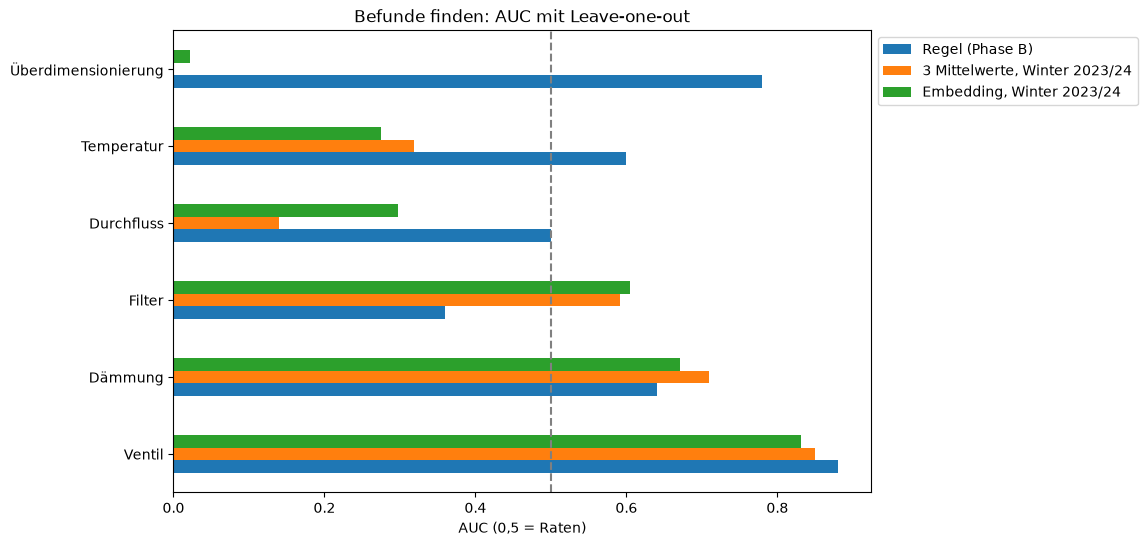

In [23]:
ax = vergleich.plot.barh(figsize=(9, 6))
ax.set_title("Befunde finden: AUC mit Leave-one-out")
ax.set_xlabel("AUC (0,5 = Raten)")
ax.set_ylabel("")
ax.legend(["Regel (Phase B)", "3 Mittelwerte, Winter 2023/24", "Embedding, Winter 2023/24"],
          loc="upper left", bbox_to_anchor=(1, 1))
ax.axvline(0.5, color="gray", linestyle="--")

In [24]:
ax.figure.savefig(BILDER / "16_befunde_auc.png", bbox_inches="tight")

- Ventil: Regel 0,88, Mittelwerte 0,85, Embedding 0,83. Dämmung: 0,64, 0,71, 0,67. Alle gleichauf, die Unterschiede sind viel kleiner als die Unsicherheit aus Phase B (Bootstrap Dämmung 0,46 bis 0,81).
- Für die Befunde bringt das LSTM nichts über die Mittelwerte hinaus. Zum Wiedererkennen braucht man viele kleine Eigenheiten, wie einen Fingerabdruck. Ein offenes Ventil ist eine grobe Abweichung, wie Fieber, da reicht ein Thermometer. Und aus 11 Ventilfällen lernt die logistische Regression mit 3 klaren Zahlen leichter als mit 8 ohne Namen.

## Schritt 17: Kein LSTM direkt auf die Befunde

Warum nicht gleich ein LSTM auf die Befunde trainieren? Das LSTM aus Phase D hat so viele gelernte Zahlen:

In [36]:
import torch

zustand = torch.load(ROOT / "notebooks" / "models" / "lernpfad" / "embedding_8.pt")
sum(w.numel() for w in zustand.values())

283856

283.856 Zahlen, für das Ventil gibt es 11 Fälle. Direkt auf die Befunde trainiert, würde das LSTM jede Station auswendig lernen (in Phase B reichten schon 10 Spalten Zufallszahlen für eine AUC von 0,75 auf den Lernstationen). Deshalb lernt das LSTM ohne Befunde aus 24.684 Tagen, und die Befunde sieht nur die logistische Regression mit 9 Zahlen.

### Varianten ohne Befunde auswählen

Statt 8 könnte der Engpass auch 4 oder 16 Zahlen haben. Wer bei den Befunden die beste Variante aussucht, hat wieder auf die Antworten geschaut. Ausgewählt wird deshalb nur mit Messungen ohne Befunde: Validierungsfehler und Wiedererkennung. Dafür die Vorbereitung aus Phase D (`naechster_tag`, weil `naechster` oben schon vergeben ist):

In [27]:
import copy
import torch

geraet = "cuda" if torch.cuda.is_available() else "cpu"

In [28]:
info["woche"] = info["tag"].dt.to_period("W").astype(str)
test = info["tag"] >= "2024-06-01"
wochen = info.loc[~test, "woche"].unique()
np.random.seed(0)
val_wochen = np.random.choice(wochen, size=int(0.1 * len(wochen)), replace=False)
val = info["woche"].isin(val_wochen) & ~test
train = ~test & ~val

In [29]:
naechster_tag = info.groupby("zaehler")["tag"].shift(-1)
paar = (naechster_tag - info["tag"]) == pd.Timedelta(days=1)
heute = np.where(paar)[0]
morgen = heute + 1

In [30]:
mittel = X[train.values].mean(axis=(0, 1))
streuung = X[train.values].std(axis=(0, 1))
X_s = (X - mittel) / streuung
ist_train = train.values[morgen]
ist_val = val.values[morgen]
ziel3 = X_s[morgen][:, :, :3].reshape(len(heute), 72)
aussen_morgen = X_s[morgen][:, :, 3]

In [31]:
class Embedding(torch.nn.Module):
    def __init__(self, gedaechtnis, kern):
        super().__init__()
        self.lstm = torch.nn.LSTM(input_size=4, hidden_size=gedaechtnis, batch_first=True)
        self.zum_kern = torch.nn.Linear(gedaechtnis, kern)
        self.decoder = torch.nn.Sequential(
            torch.nn.Linear(kern + 24, 128),
            torch.nn.ReLU(),
            torch.nn.Linear(128, 72),
        )

    def einbetten(self, x):
        ausgabe, (h, c) = self.lstm(x)
        return self.zum_kern(h[-1])

    def forward(self, x, aussen):
        kern = self.einbetten(x)
        return self.decoder(torch.cat([kern, aussen], dim=1))

In [32]:
fehler = torch.nn.MSELoss()
x_tr = torch.tensor(X_s[heute][ist_train], dtype=torch.float32, device=geraet)
a_tr = torch.tensor(aussen_morgen[ist_train], dtype=torch.float32, device=geraet)
y_tr = torch.tensor(ziel3[ist_train], dtype=torch.float32, device=geraet)
x_va = torch.tensor(X_s[heute][ist_val], dtype=torch.float32, device=geraet)
a_va = torch.tensor(aussen_morgen[ist_val], dtype=torch.float32, device=geraet)
y_va = torch.tensor(ziel3[ist_val], dtype=torch.float32, device=geraet)

Auswahlregel, vor dem Training festgelegt: Wir nehmen die Variante mit dem kleinsten Validierungsfehler. Erwartung: Ab einem Punkt werden mehr Zahlen schlechter.

In [33]:
varianten = []
embeddings = {}

for kern in [4, 8, 16]:
    torch.manual_seed(0)
    m_k = Embedding(gedaechtnis=256, kern=kern).to(geraet)
    optimierer = torch.optim.Adam(m_k.parameters(), lr=0.001)
    bester_fehler = float("inf")
    geduld = 0

    for runde in range(300):
        m_k.train()
        reihenfolge = torch.randperm(len(x_tr), device=geraet)
        for start in range(0, len(x_tr), 256):
            stapel = reihenfolge[start:start + 256]
            optimierer.zero_grad()
            loss = fehler(m_k(x_tr[stapel], a_tr[stapel]), y_tr[stapel])
            loss.backward()
            optimierer.step()

        m_k.eval()
        with torch.no_grad():
            f_val = fehler(m_k(x_va, a_va), y_va).item()
        if f_val < bester_fehler:
            bester_fehler = f_val
            bester_stand = copy.deepcopy(m_k.state_dict())
            geduld = 0
        else:
            geduld = geduld + 1
            if geduld == 20:
                break

    m_k.load_state_dict(bester_stand)
    teile = []
    with torch.no_grad():
        for start in range(0, len(X_s), 4096):
            stueck = torch.tensor(X_s[start:start + 4096], dtype=torch.float32, device=geraet)
            teile.append(m_k.einbetten(stueck).cpu().numpy())
    embeddings[kern] = np.concatenate(teile)

    e1 = pd.DataFrame(embeddings[kern][w1.values]).groupby(info["zaehler"][w1].values).mean()
    e2 = pd.DataFrame(embeddings[kern][w2.values]).groupby(info["zaehler"][w2].values).mean()
    a = cdist(e1, e2)
    varianten.append({"kern": kern, "validierungsfehler": bester_fehler,
                      "wiedererkannt": (e2.index[a.argmin(axis=1)] == e1.index).sum()})

varianten = pd.DataFrame(varianten)
varianten

,kern,validierungsfehler,wiedererkannt
0,4,0.201333,17
1,8,0.192499,19
2,16,0.190611,20


- Bei 8 kommt wieder 0,1925 und 19 heraus wie in Phase D und Schritt 15, das Training ist wiederholbar.
- Erwartung nicht bestätigt: Bis 16 wird es mit jeder Stufe leicht besser. Von 4 auf 8 ist der Gewinn deutlich, von 8 auf 16 kaum noch.
- Nach der Regel: 16. Erst jetzt die gewählte Variante bei den Befunden, gleich mit Zufallstest:

In [34]:
e2_16 = pd.DataFrame(embeddings[16][w2.values]).groupby(info["zaehler"][w2].values).mean()
daten_16 = e2_16.join(labels)

In [35]:
np.random.seed(0)
ergebnis_16 = []
for b in befunde:
    d = daten_16.dropna(subset=[b])
    y = d[b].astype(int)
    v = cross_val_predict(modell, d[list(range(16))], y, cv=LeaveOneOut(), method="predict_proba")[:, 1]
    echt = roc_auc_score(y, v)
    zufall = []
    for i in range(100):
        gemischt = y.sample(frac=1).values
        v = cross_val_predict(modell, d[list(range(16))], gemischt, cv=LeaveOneOut(), method="predict_proba")[:, 1]
        zufall.append(roc_auc_score(gemischt, v))
    ergebnis_16.append({"befund": b, "auc": echt, "zufall_anteil": (np.array(zufall) >= echt).mean()})
ergebnis_16 = pd.DataFrame(ergebnis_16)
ergebnis_16.round(2)

,befund,auc,zufall_anteil
0,ventil,0.79,0.00
1,daemmung,0.68,0.03
2,filter,0.69,0.02
3,durchfluss,0.53,0.25
4,temperatur,0.25,0.96
5,ueberdimensioniert,0.35,0.81


- Ventil 0,79, Dämmung 0,68: nicht besser als mit 8 Zahlen. Besser vorhersagen und wiedererkennen heißt nicht besser Fehler finden.
- Filter 0,69, nur 2 von 100 zufällig so gut. Aber: Bei 12 Tests (6 Befunde × 2 Varianten) mit der Grenze 5 von 100 erwartet man 12 × 0,05 = 0,6 Zufallstreffer. Nicht erwartet und nur in einer Variante, also nur ein Hinweis.

## Ergebnis Phase E

- Der Steckbrief einer Station ist der Durchschnitt der 8 Zahlen über ihre Wintertage.
- Wiedererkennung über zwei Winter: LSTM 19 von 23, typischer Wintertag (72 Zahlen) 15, Mittelwerte 13, Raten 0,4. In den 8 Zahlen steckt, wie eine Station tickt.
- Bei den Befunden ist das Embedding nicht besser als 3 Mittelwerte oder die Regel aus Phase B. Echt sind nur Ventil und Dämmung. Die Überdimensionierung braucht den Vertrag.
- Kein LSTM direkt auf die Befunde: 283.856 Zahlen gegen 11 Ventilfälle wäre Auswendiglernen.
- Varianten ohne Befunde ausgewählt (16 Zahlen), bei den Befunden nicht besser als 8.
- Die Stärke zeigt sich bei 68956372: Verändert sich eine Station, verändert sich ihr Steckbrief. In Phase F wird deshalb jede Station mit sich selbst verglichen.